## **Double gyre flow**


In [36]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

from ipywidgets import interact, FloatSlider, IntSlider, fixed
import matplotlib.patches as patches

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import ROMDataManager
from src.engine import SHREDEngine
from src.train import fit, fit2, evaluate, evaluate2
from src.mSHRED.mSRED import mSHRED

np.random.seed(2025)

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# additional imports for DGF
from helpers import DGFsimulation

## Solver

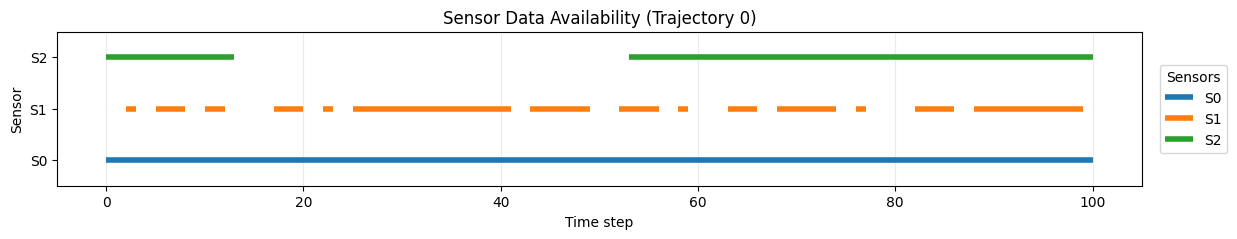

Shape of U:	 (100, 101, 1250) 	Shape of Uraw:	 (100, 101, 50, 25)
Shape of V:	 (100, 101, 1250) 	Shape of Vraw:	 (100, 101, 50, 25)
measurements:	 (100, 101, 3)


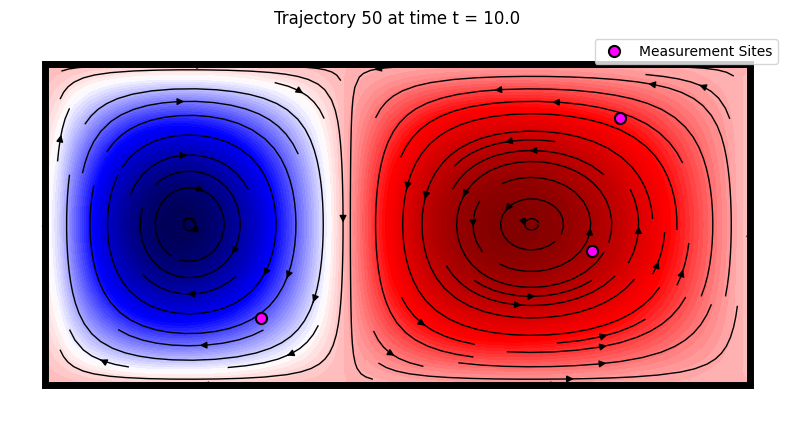

In [38]:
# generate DGF data 
simulator    = DGFsimulation(ntrajectories=100)
Uraw, Vraw   = simulator.generate_data()
U, V         = simulator.get_reshaped_data()
measurements = simulator.generate_measurements_U(
    nsensors=3, idx_short_broken=[1], idx_long_broken=[2], verbose=True, positions=[ 960,  380, 1020]
)

# Debugging 
print("Shape of U:\t", U.shape, "\tShape of Uraw:\t", Uraw.shape)
print("Shape of V:\t", V.shape, "\tShape of Vraw:\t", Vraw.shape)
print("measurements:\t", measurements.shape)
simulator.plot_data(which_trajectory=50)

In [39]:
## Errors
ERRORS = []

## Hyperparameters
LAGS = 25
COMPRESS = 4
TRAIN_SIZE = 0.8
VAL_SIZE = 0.1
TEST_SIZE = 0.1

OPTIMIZER = "AdamW"
LEARNING_RATE = 1e-3
NUM_EPOCHS = 200
BATCH_SIZE = 32
PATIENCE = 40
VERBOSE_TRAIN = True

TR_ENCODER_DEPTH = 1
TR_N_HEADS = 4
TR_DIM_FEEDFORWARD = 64
TR_HIDDEN_SIZE = 32
TR_DROPOUT = 0.1

GRUD_HIDDEN_SIZE = 32
GRUD_DROPOUT = 0.1

## (T.0) only availabe sensors

In [40]:
# remove the sensors with failed measurements from the data

#vector of always available sensors (i.e. not broken) 
#like we aren't aware of how data are generated
mask = ~np.isnan(measurements).any(axis=(0,1))
measurements_av = measurements[:, :, mask]
print("Available sensors:\t", np.where(mask)[0])

Available sensors:	 [0]


In [41]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(U, id = "U" , compress = COMPRESS, scaler="minmax", measurements = measurements_av)
manager.add_data(V, id = "V" , compress = COMPRESS, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 1]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])

Input shape for the model: 1
Output shape for the model: 8


Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training: 100%|██████████| 200/200 [06:53<00:00,  2.07s/it, Train Loss=0.0020, Val Loss=0.0024, Patience=27, Best Val Loss=0.0021, LR=1.00e-03]

Training completed with best validation loss: 0.0021


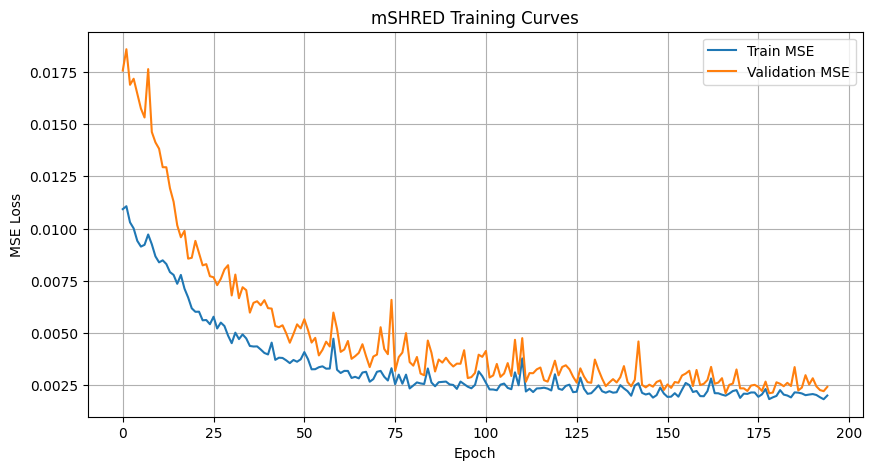

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563


In [42]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,
 )

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.0) only available sensors",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse), 
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 8.855%	V: 9.831%


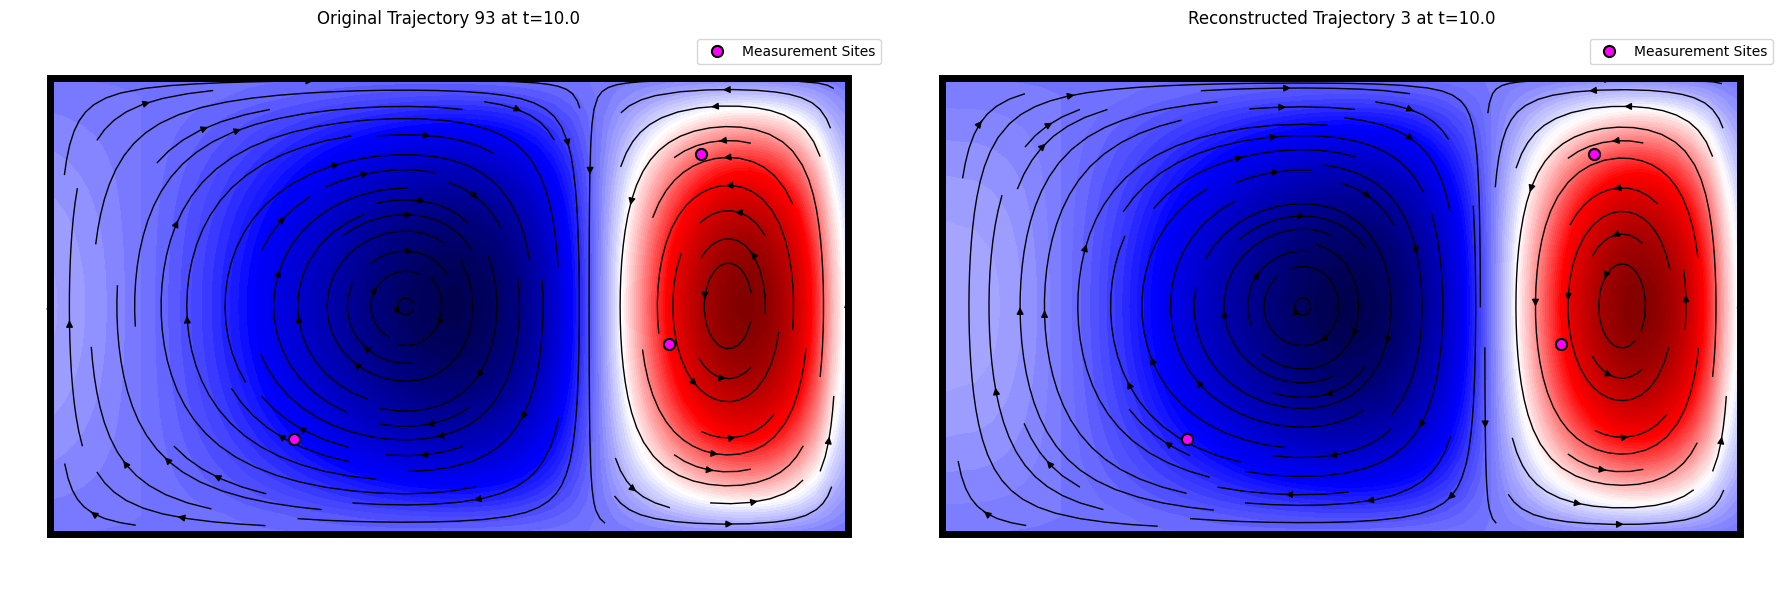

In [43]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred


interact(
    simulator.plot_comparison, 
    test_reconstruction=fixed(test_reconstruction), 
    test_idx=fixed(manager.test_indices), 
    which_trajectory=IntSlider(min=0, max=len(manager.test_indices)-1, step=1, value=0), 
    which_time=IntSlider(min=0, max = len(simulator.t)-1, step=1, value=0)
);

## (T.1.A): Median imputer

In [44]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(U, id = "U" , compress = COMPRESS, scaler="minmax", measurements = measurements, imputer="median")
manager.add_data(V, id = "V" , compress = COMPRESS, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


Starting training...


Training: 100%|██████████| 200/200 [13:38<00:00,  4.09s/it, Train Loss=0.0003, Val Loss=0.0005, Patience=7, Best Val Loss=0.0004, LR=1.00e-03] 

Training completed with best validation loss: 0.0004


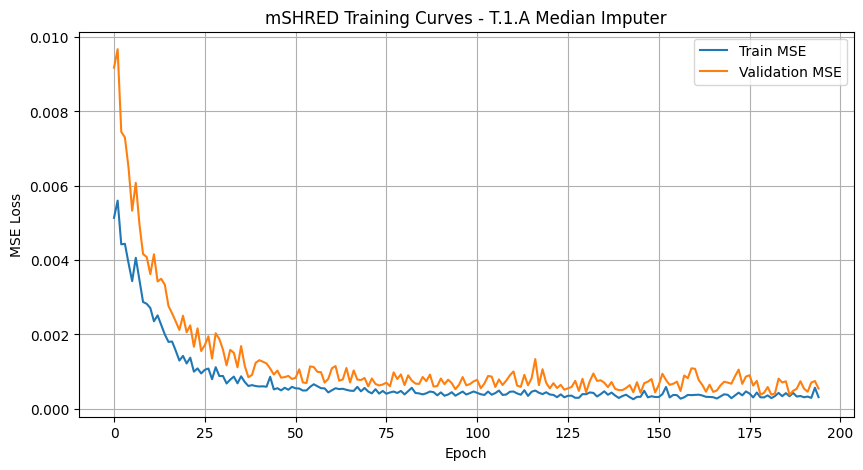

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053


In [45]:
# mSHRED TRAINING + EVALUATION (T.1.A)
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,
)

# Plot training curves (T.1.A)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.1.A Median Imputer')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.1.A) median imputer",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 2.419%	V: 2.751%


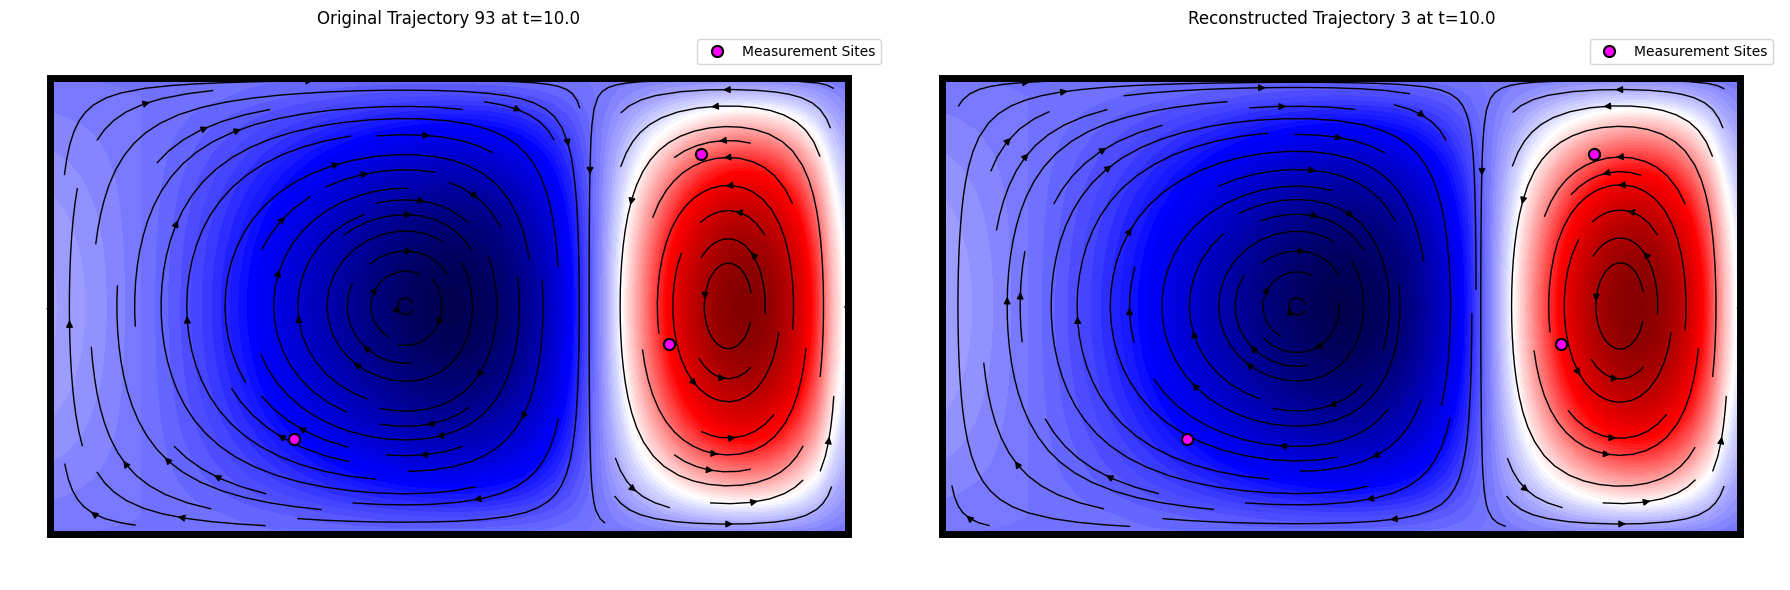

In [46]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred

## (T.1.B): Mean imputer

In [47]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(U, id = "U" , compress = COMPRESS, scaler="minmax", measurements = measurements, imputer="mean")
manager.add_data(V, id = "V" , compress = COMPRESS, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


Starting training...


Training:  63%|██████▎   | 126/200 [03:12<01:52,  1.52s/it, Train Loss=0.0004, Val Loss=0.0009, Patience=39, Best Val Loss=0.0006, LR=1.00e-03]

Early stopping at epoch 127
Training completed with best validation loss: 0.0006


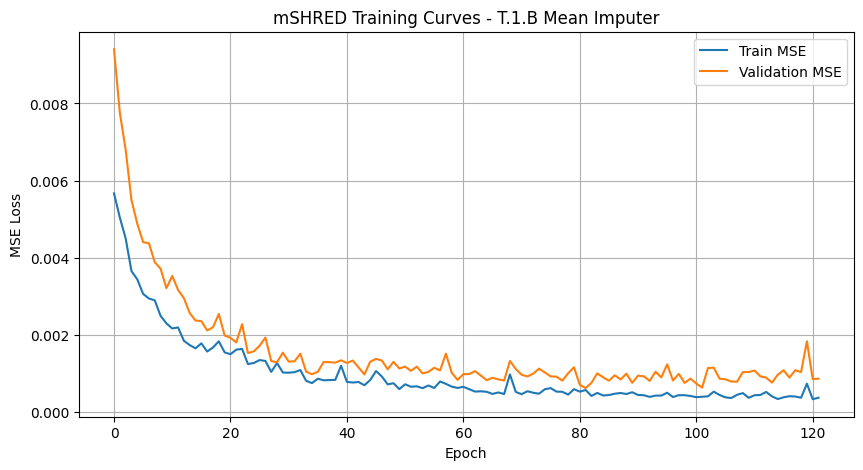

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153


In [48]:
# mSHRED TRAINING + EVALUATION (T.1.B)
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,
 )

# Plot training curves (T.1.B)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.1.B Mean Imputer')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.1.B) mean imputer",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 4.093%	V: 4.562%


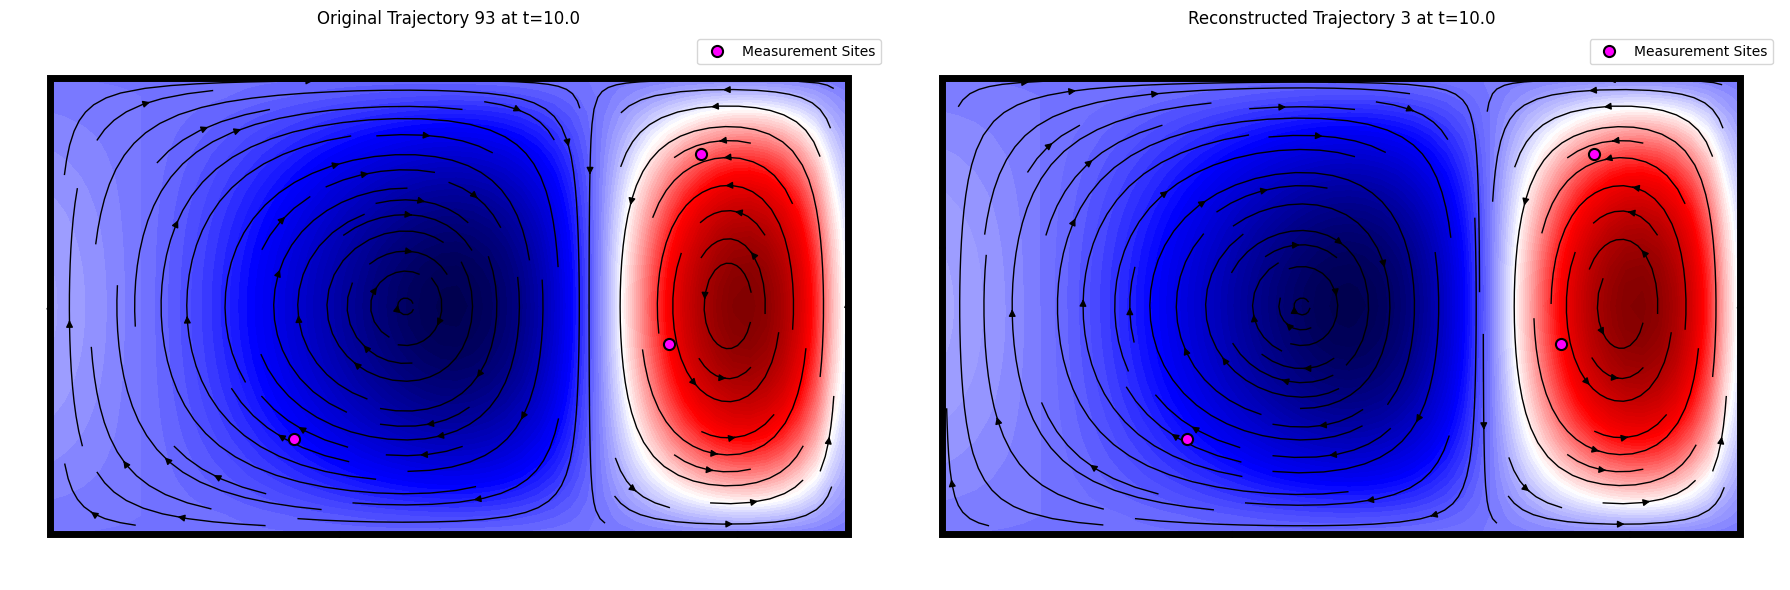

In [49]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred

## (T.1.C): Last value imputer

In [50]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(U, id = "U" , compress = COMPRESS, scaler="minmax", measurements = measurements, imputer="last_value")
manager.add_data(V, id = "V" , compress = COMPRESS, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


Starting training...


Training:  92%|█████████▏| 183/200 [04:44<00:26,  1.56s/it, Train Loss=0.0003, Val Loss=0.0007, Patience=39, Best Val Loss=0.0007, LR=1.00e-03]

Early stopping at epoch 184
Training completed with best validation loss: 0.0007


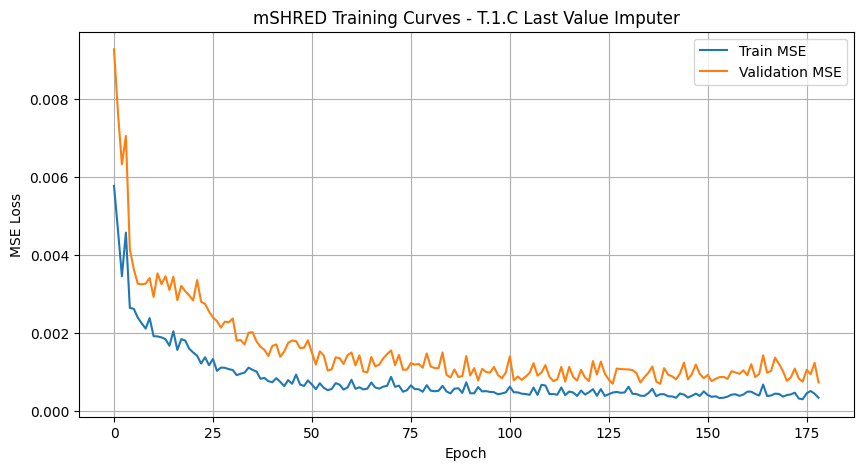

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495


In [51]:
# mSHRED TRAINING + EVALUATION (T.1.C)
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,
 )

# Plot training curves (T.1.C)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.1.C Last Value Imputer')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.1.C) last value imputer",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 3.630%	V: 4.076%


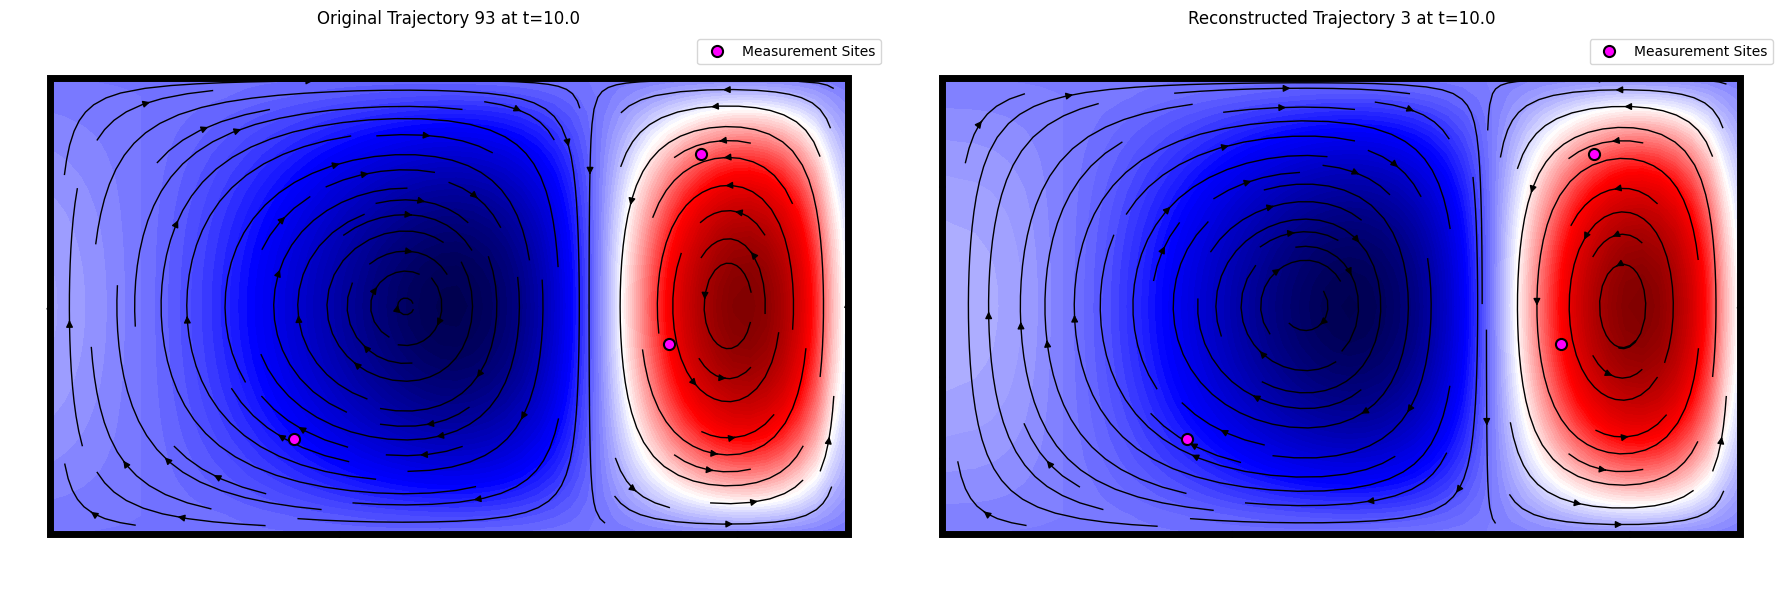

In [52]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred

## (T.2.A) GRUD

In [53]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(U, id = "U" , compress = COMPRESS, scaler="minmax", measurements = measurements)
manager.add_data(V, id = "V" , compress = COMPRESS, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose = True, masking_type="grud")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset[0][0].shape[2]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 6529
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 4, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 4, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 4, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


Starting training...


Training: 100%|██████████| 200/200 [05:45<00:00,  1.73s/it, Train Loss=0.0002, Val Loss=0.0004, Patience=4, Best Val Loss=0.0003, LR=1.00e-03]

Training completed with best validation loss: 0.0003


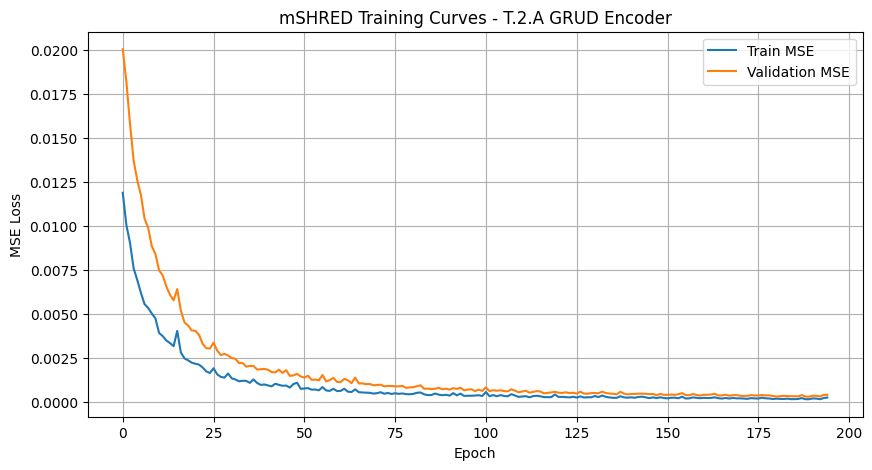

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853


In [ ]:
# mSHRED TRAINING + EVALUATION (T.2.A) 
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=GRUD_HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=GRUD_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,
)

# Plot training curves (T.2.A)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.2.A GRUD Encoder')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + MLP", "type" : "(T.2.A) GRUD encoder",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}   

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Mean Relative Error (MRE): 	U: 2.277%	V: 2.547%


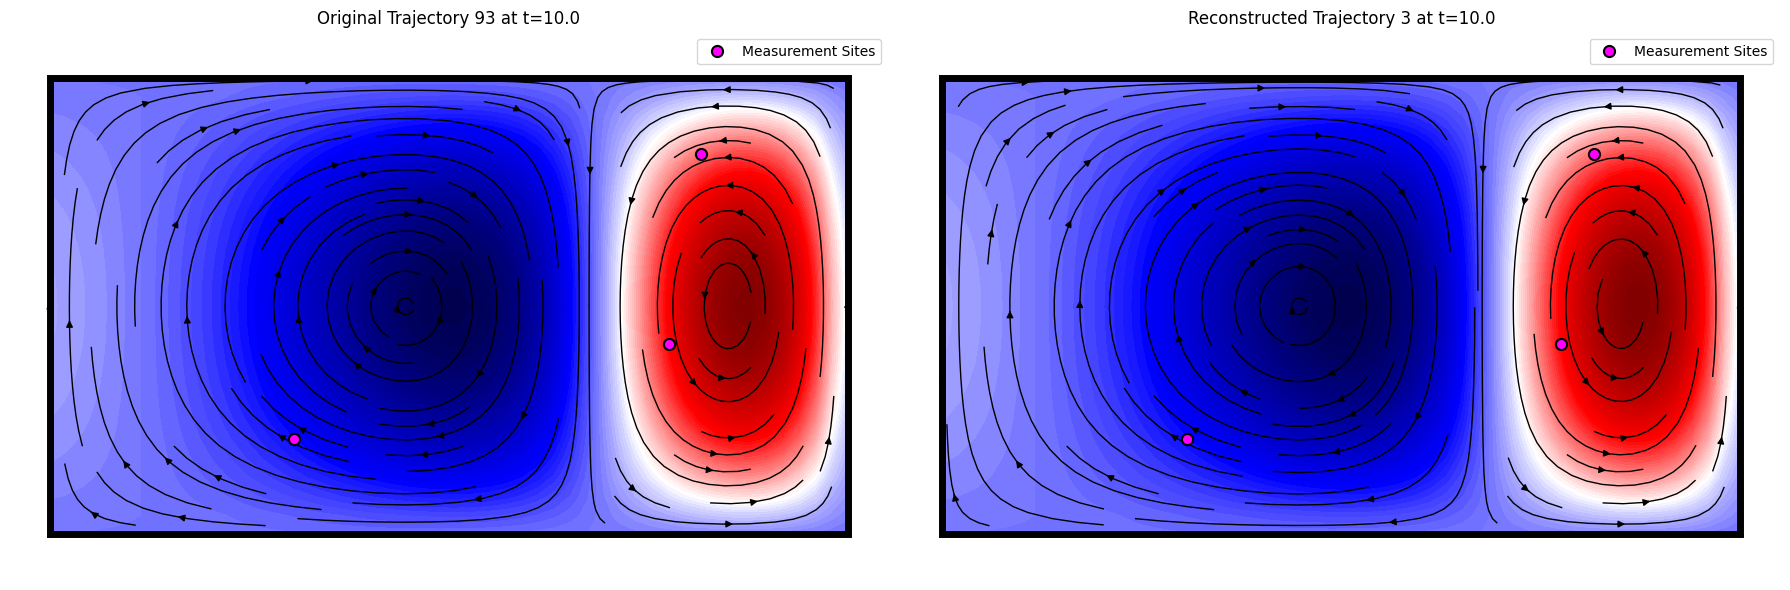

In [55]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

## (T.2.B): Attn-GRUD

Starting training...


Training: 100%|██████████| 200/200 [16:59<00:00,  5.10s/it, Train Loss=0.0002, Val Loss=0.0004, Patience=1, Best Val Loss=0.0004, LR=1.00e-03] 

Training completed with best validation loss: 0.0004


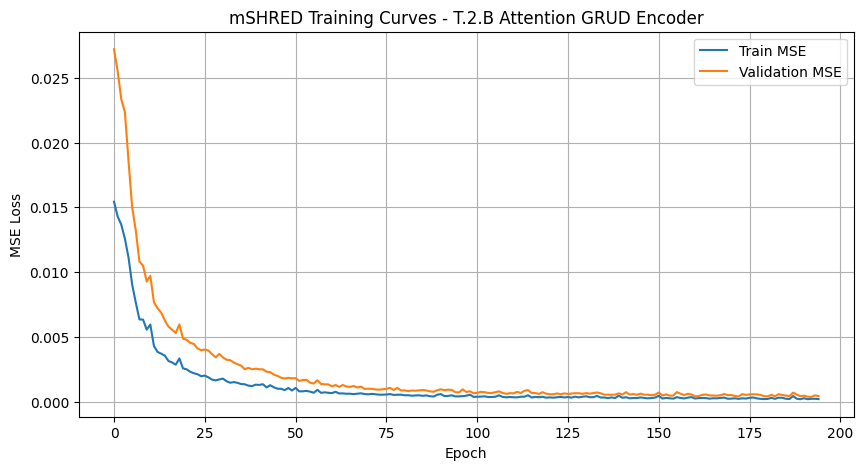

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041


In [56]:
# mSHRED TRAINING + EVALUATION (T.2.B) 
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=GRUD_HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=GRUD_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,
)

# Plot training curves (T.2.B)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.2.B Attention GRUD Encoder')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + MLP", "type" : "(T.2.B) Attention GRUD encoder",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}   

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Mean Relative Error (MRE): 	U: 2.313%	V: 2.623%


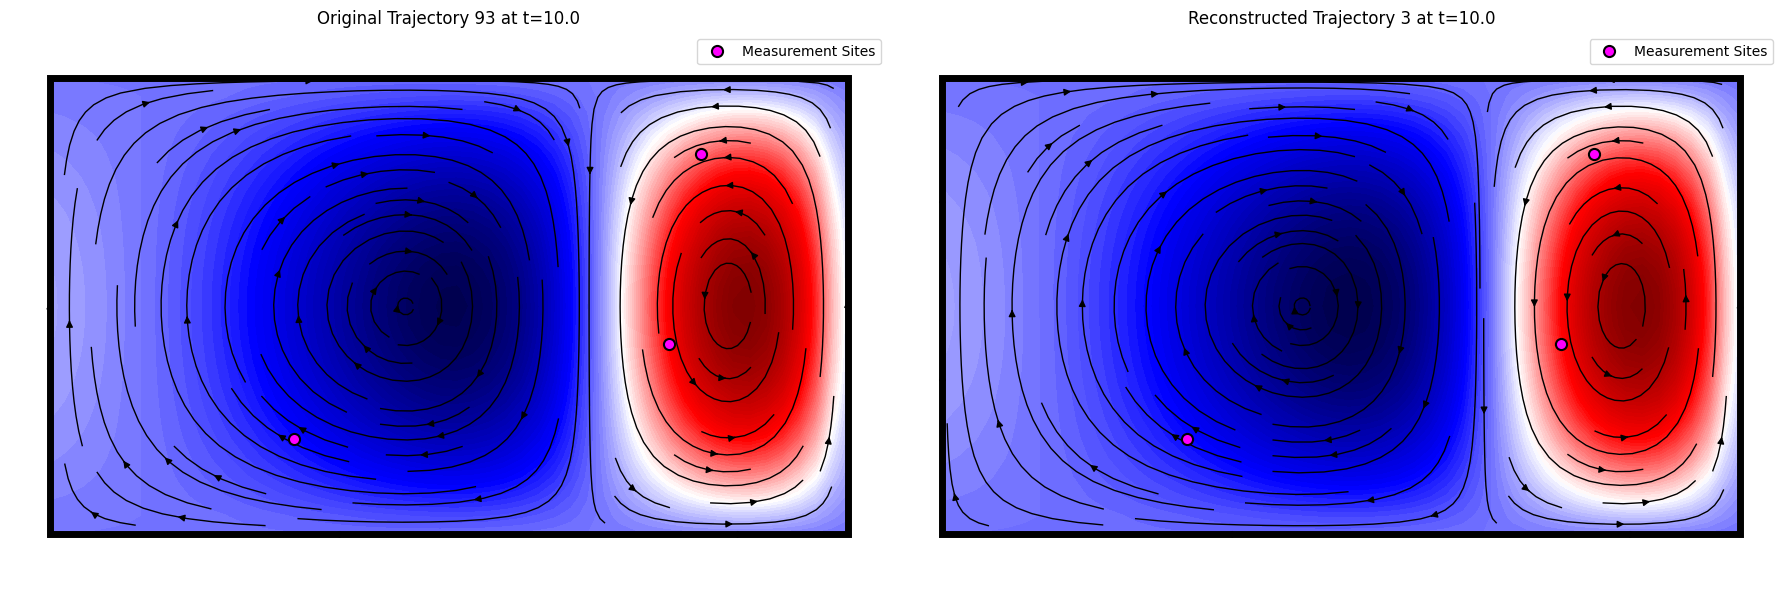

In [57]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred

## (T.3.A): Masking

In [69]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(U, id = "U" , compress = COMPRESS, scaler="minmax", measurements = measurements)
manager.add_data(V, id = "V" , compress = COMPRESS, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, masking_type="mask_data")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][2].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 6529
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']

Number of nan values in sensor measurements after masking: 6529

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training:  88%|████████▊ | 176/200 [07:52<01:04,  2.69s/it, Train Loss=0.0002, Val Loss=0.0003, Patience=39, Best Val Loss=0.0002, LR=1.00e-03]

Early stopping at epoch 177
Training completed with best validation loss: 0.0002


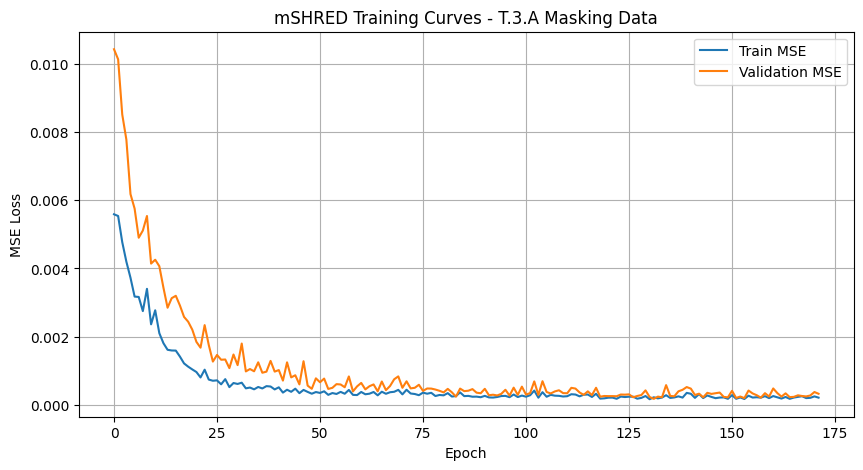

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836


In [66]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset, masking_type="mask_data",
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,  
)

# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.3.A Masking Data')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate2(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate2(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.3.A) masking data",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),  
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 2.345%	V: 2.606%


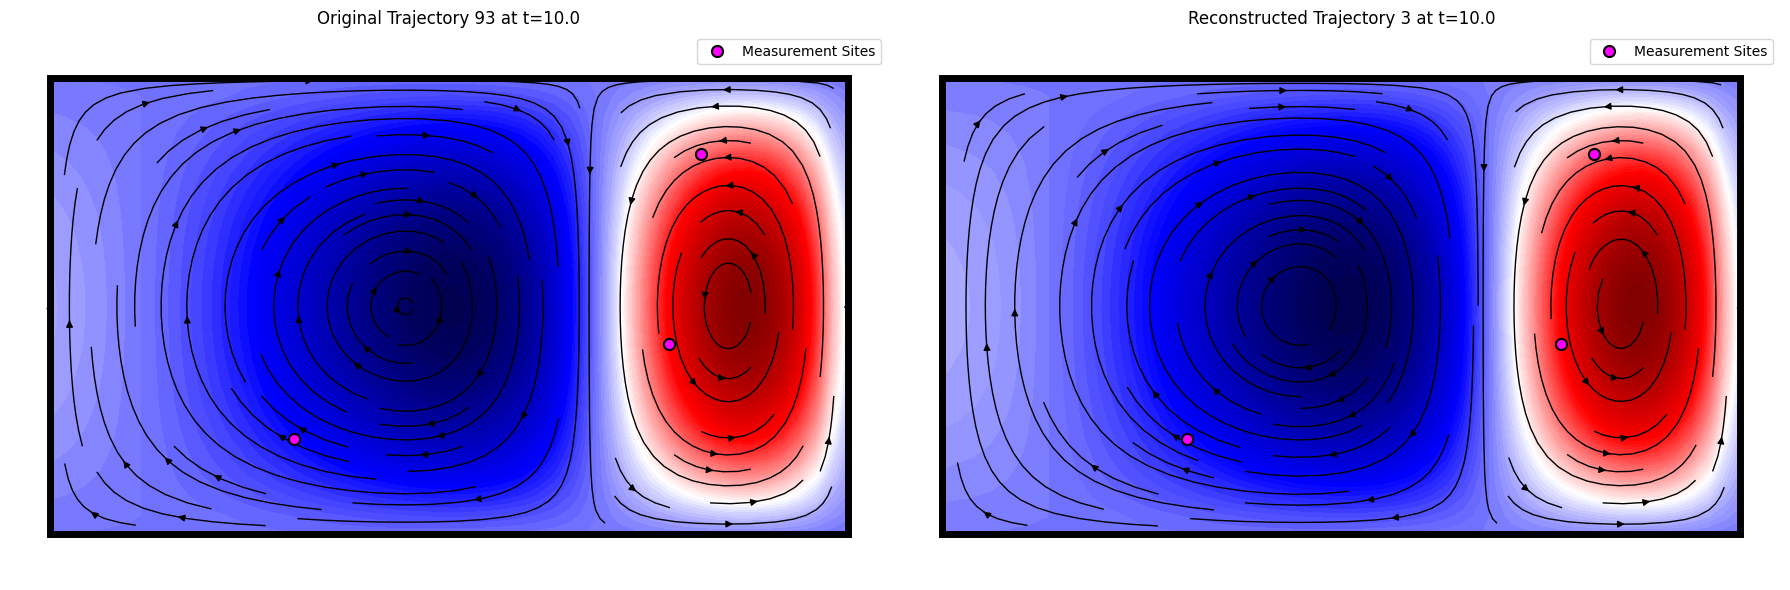

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)


## (T.3.B): Masking x2 channels

Starting training...


Training:  91%|█████████ | 182/200 [05:27<00:32,  1.80s/it, Train Loss=0.0002, Val Loss=0.0005, Patience=39, Best Val Loss=0.0001, LR=1.00e-03]

Early stopping at epoch 183
Training completed with best validation loss: 0.0001


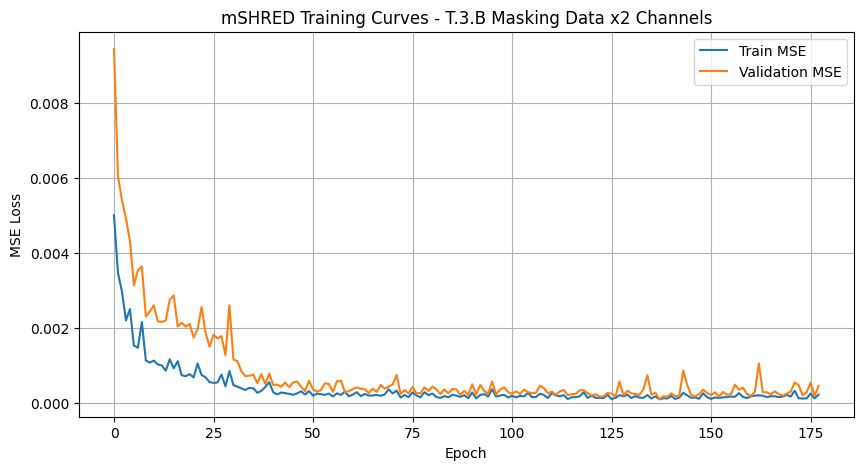

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836
7,(mSHRED): TR + MLP,(T.3.B) masking data x2 channels,0.000095,0.000095,0.000120,0.009714,0.011310,0.010306


In [70]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = True,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset, masking_type="mask_data",
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,  
)

# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.3.B Masking Data x2 Channels')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate2(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate2(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.3.B) masking data x2 channels",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),  
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 1.225%	V: 1.348%


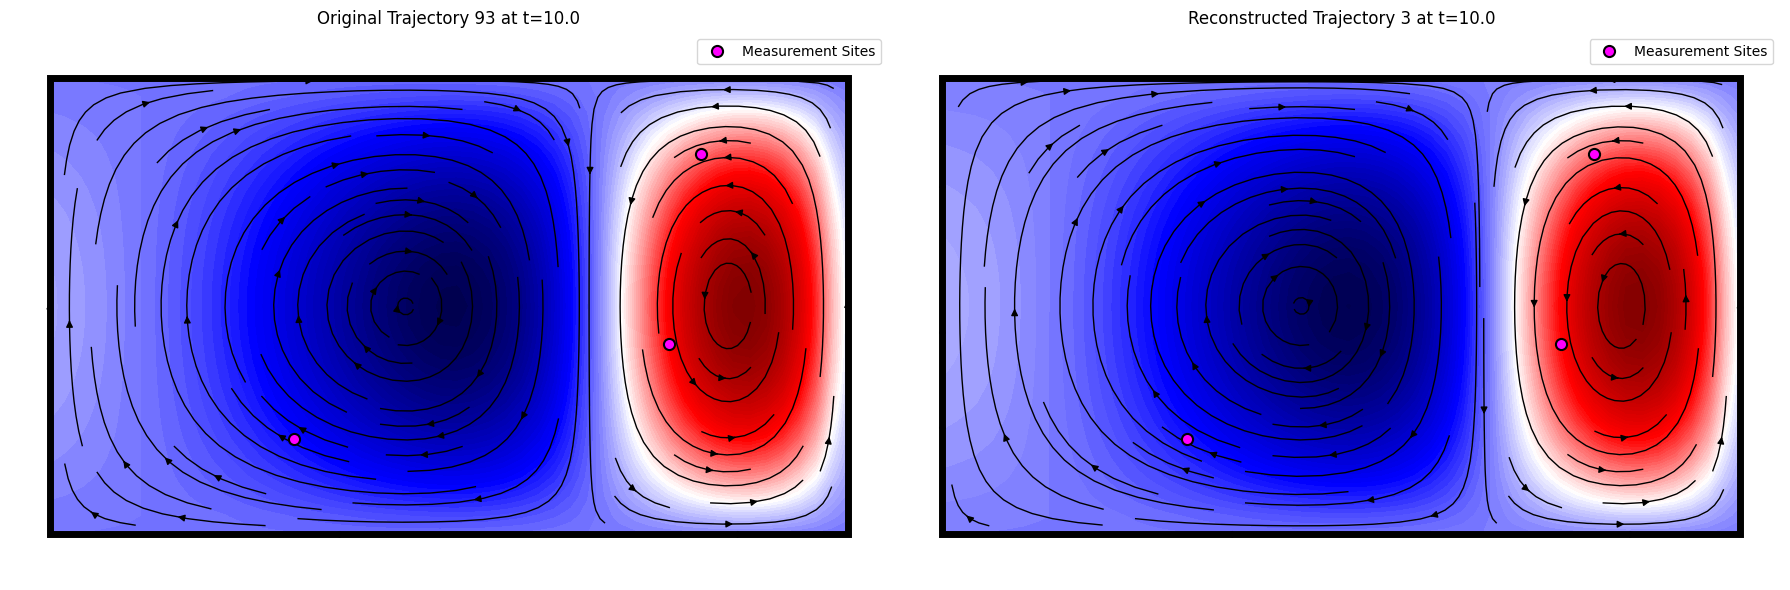

In [71]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)


## (T.3.C): Masking hidden space

Starting training...


Training:  75%|███████▌  | 150/200 [04:05<01:21,  1.63s/it, Train Loss=0.0002, Val Loss=0.0004, Patience=39, Best Val Loss=0.0001, LR=1.00e-03]

Early stopping at epoch 151
Training completed with best validation loss: 0.0001


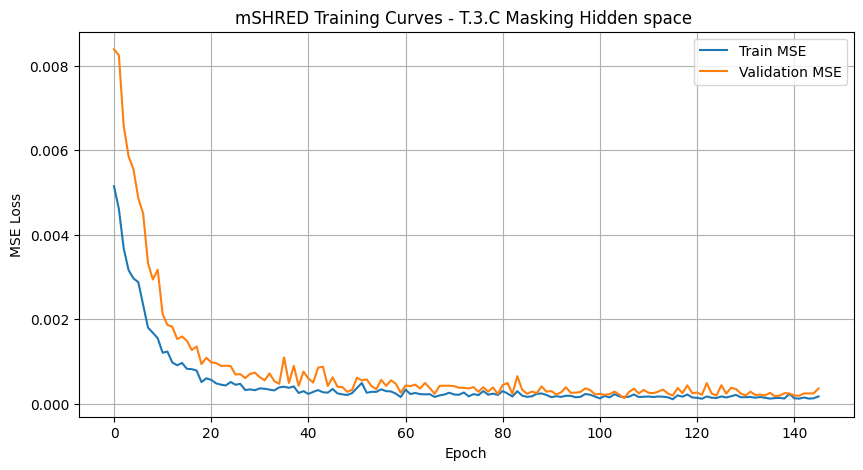

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836
7,(mSHRED): TR + MLP,(T.3.B) masking data x2 channels,0.000095,0.000095,0.000120,0.009714,0.011310,0.010306
8,(mSHRED): TR + MLP,(T.3.C) masking hidden space,0.000152,0.000127,0.000161,0.014436,0.015065,0.015629


In [72]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset, masking_type="mask_data",
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,  
)

# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.3.C Masking Hidden space ')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate2(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate2(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.3.C) masking hidden space",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),  
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 1.948%	V: 2.163%


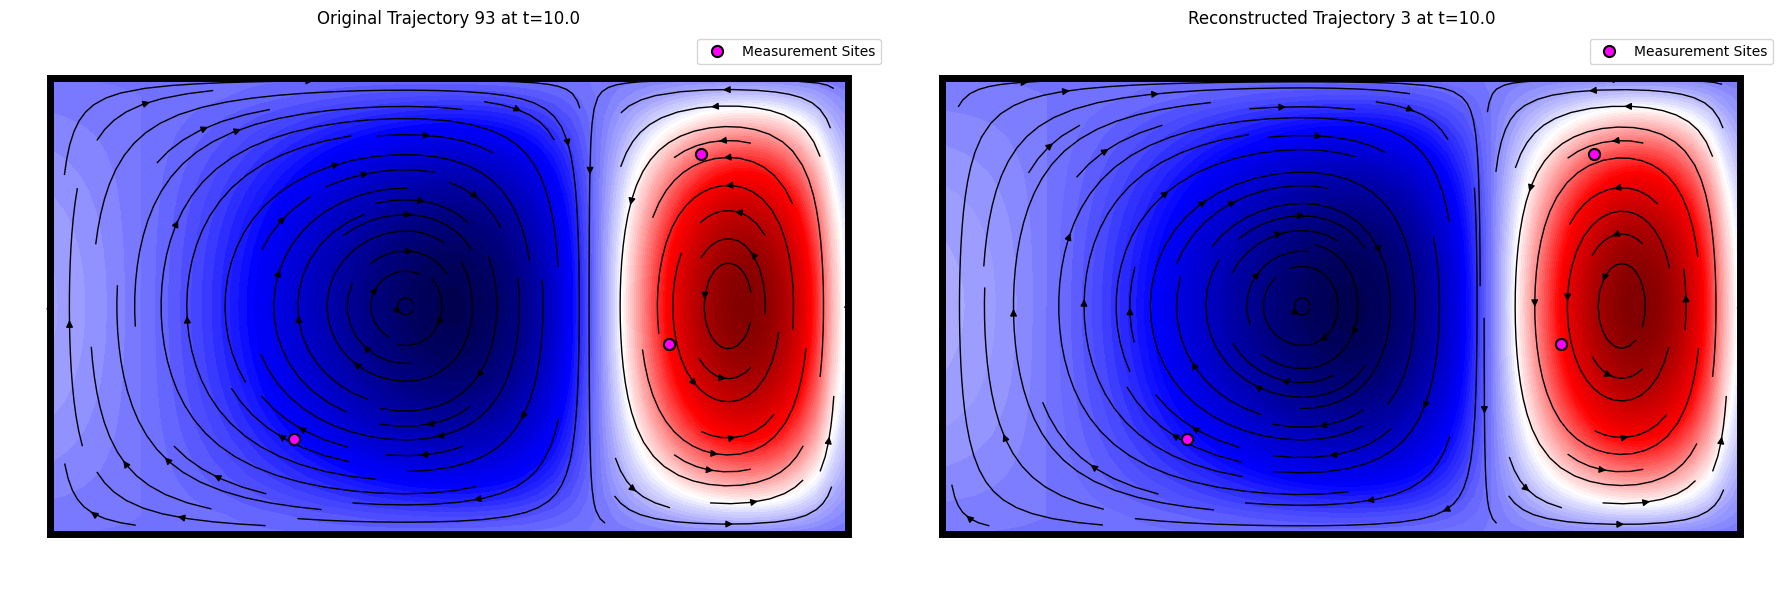

In [73]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

## (T.3.D) Masking MHSA

Starting training...


Training: 100%|██████████| 200/200 [06:50<00:00,  2.05s/it, Train Loss=0.0002, Val Loss=0.0003, Patience=23, Best Val Loss=0.0002, LR=1.00e-03]

Training completed with best validation loss: 0.0002


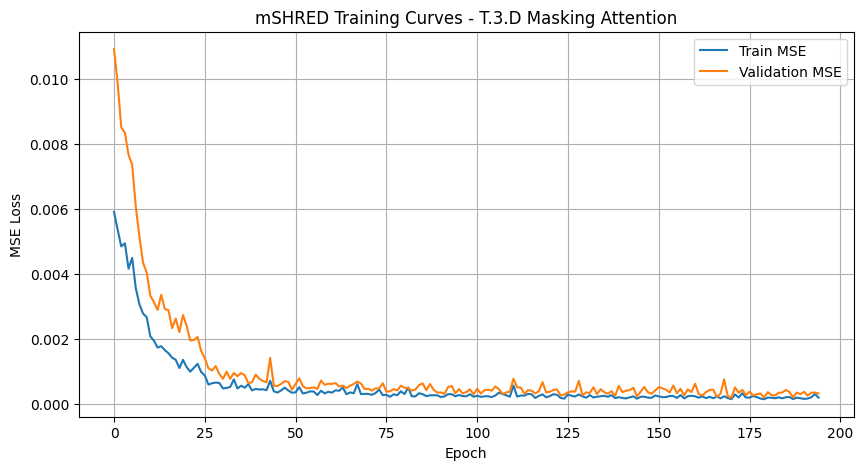

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836
7,(mSHRED): TR + MLP,(T.3.B) masking data x2 channels,0.000095,0.000095,0.000120,0.009714,0.011310,0.010306
8,(mSHRED): TR + MLP,(T.3.C) masking hidden space,0.000152,0.000127,0.000161,0.014436,0.015065,0.015629
9,(mSHRED): TR + MLP,(T.3.D) masking attention,0.000144,0.000187,0.000195,0.014519,0.016432,0.015871


In [74]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset, masking_type="mask_data",
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,  
)

# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.3.D Masking Attention')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate2(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate2(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.3.D) masking attention",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),  
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 1.841%	V: 2.053%


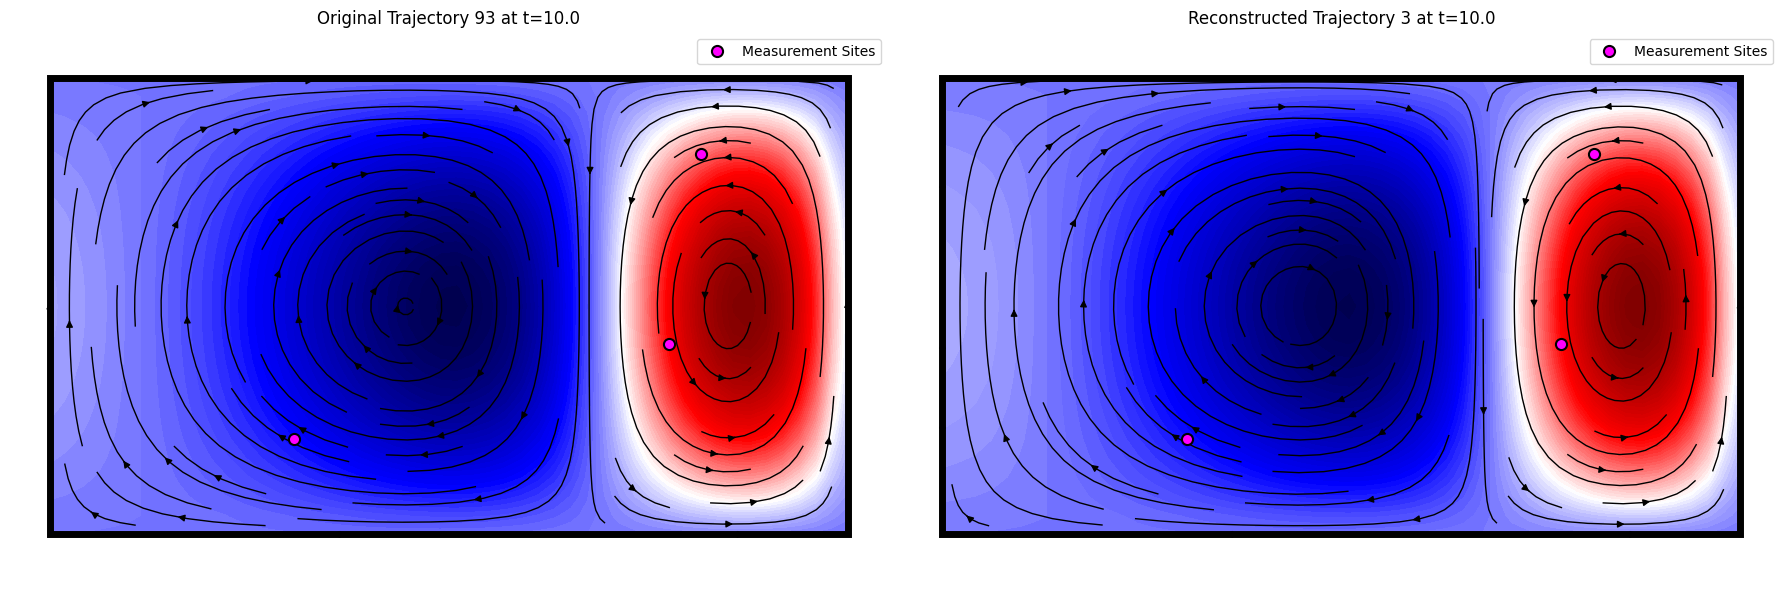

In [75]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)


## (T.3.E) Masking x2 channels + MHSA

Starting training...


Training: 100%|██████████| 200/200 [06:48<00:00,  2.04s/it, Train Loss=0.0001, Val Loss=0.0001, Patience=30, Best Val Loss=0.0001, LR=1.00e-03]

Training completed with best validation loss: 0.0001


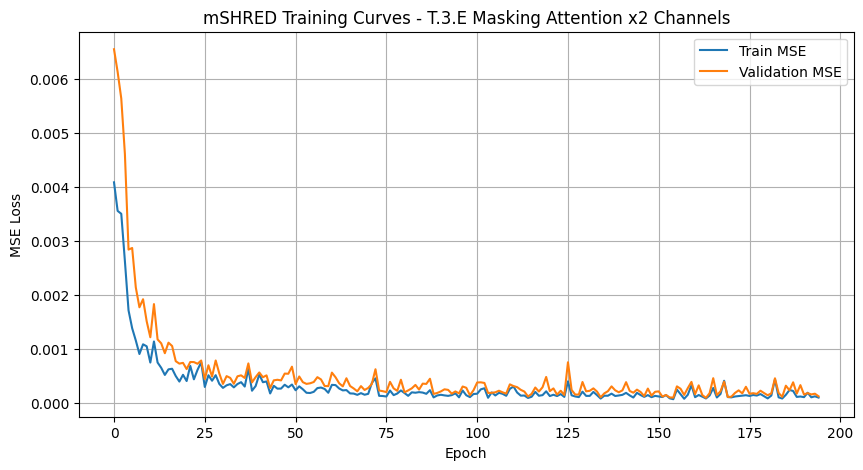

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836
7,(mSHRED): TR + MLP,(T.3.B) masking data x2 channels,0.000095,0.000095,0.000120,0.009714,0.011310,0.010306
8,(mSHRED): TR + MLP,(T.3.C) masking hidden space,0.000152,0.000127,0.000161,0.014436,0.015065,0.015629
9,(mSHRED): TR + MLP,(T.3.D) masking attention,0.000144,0.000187,0.000195,0.014519,0.016432,0.015871


In [76]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = True,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset, masking_type="mask_data",
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,  
)

# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.3.E Masking Attention x2 Channels')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate2(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate2(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.3.E) masking attention + x2 channels",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),  
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 1.606%	V: 1.790%


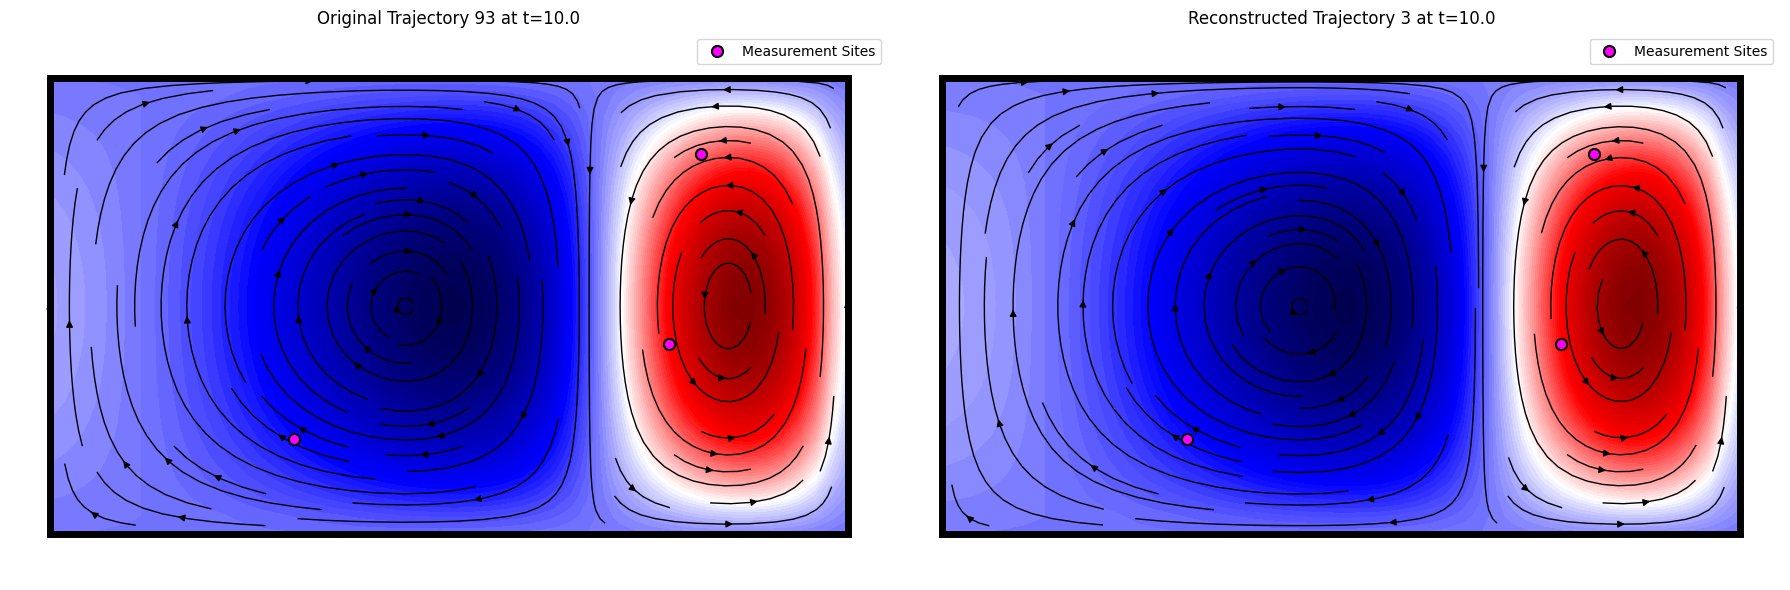

In [77]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)


## (T.3.F): Masking MHSA learned


Starting training...


Training: 100%|██████████| 200/200 [13:17<00:00,  3.99s/it, Train Loss=0.0002, Val Loss=0.0003, Patience=8, Best Val Loss=0.0002, LR=1.00e-03] 

Training completed with best validation loss: 0.0002


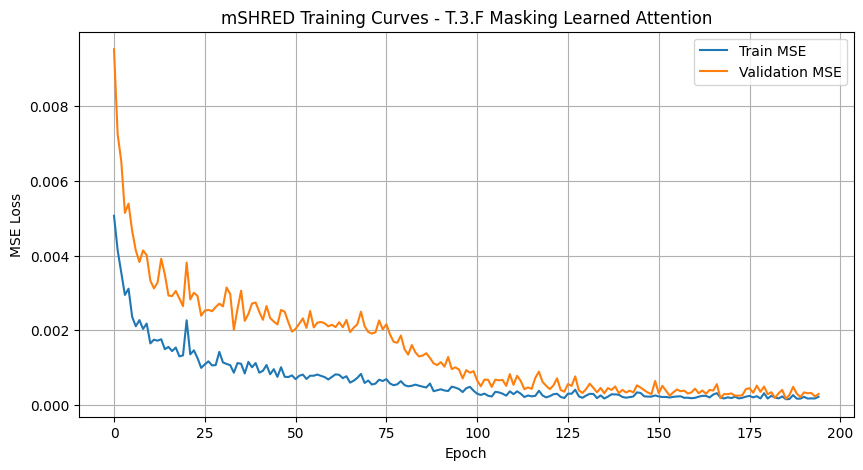

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836
7,(mSHRED): TR + MLP,(T.3.B) masking data x2 channels,0.000095,0.000095,0.000120,0.009714,0.011310,0.010306
8,(mSHRED): TR + MLP,(T.3.C) masking hidden space,0.000152,0.000127,0.000161,0.014436,0.015065,0.015629
9,(mSHRED): TR + MLP,(T.3.D) masking attention,0.000144,0.000187,0.000195,0.014519,0.016432,0.015871


In [79]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset, masking_type="mask_data",
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,  
)

# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.3.F Masking Learned Attention')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate2(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate2(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.3.D) masking learned attention",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),  
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 1.777%	V: 2.006%


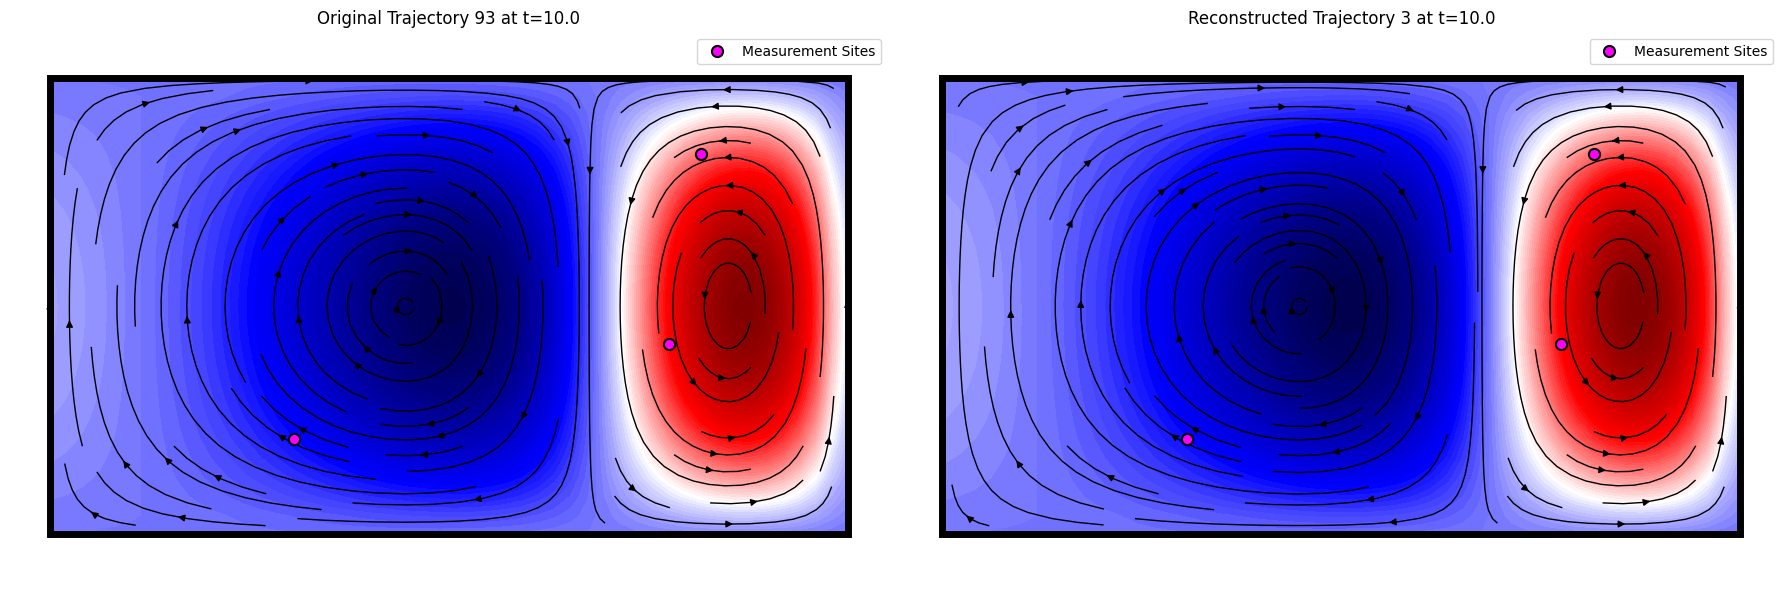

In [80]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)


## (T.3.G) Masking x2 channels + MHSA learned

Starting training...


Training: 100%|██████████| 200/200 [09:52<00:00,  2.96s/it, Train Loss=0.0001, Val Loss=0.0001, Patience=1, Best Val Loss=0.0001, LR=1.00e-03] 

Training completed with best validation loss: 0.0001


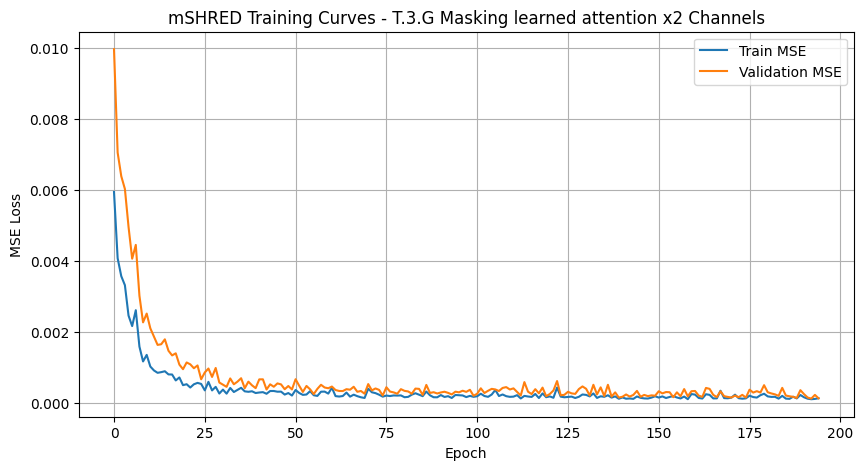

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836
7,(mSHRED): TR + MLP,(T.3.B) masking data x2 channels,0.000095,0.000095,0.000120,0.009714,0.011310,0.010306
8,(mSHRED): TR + MLP,(T.3.C) masking hidden space,0.000152,0.000127,0.000161,0.014436,0.015065,0.015629
9,(mSHRED): TR + MLP,(T.3.D) masking attention,0.000144,0.000187,0.000195,0.014519,0.016432,0.015871


In [81]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=TR_ENCODER_DEPTH, input_size=nn_input_shape, n_heads=TR_N_HEADS,
    dim_feedforward=TR_DIM_FEEDFORWARD, hidden_size=TR_HIDDEN_SIZE, input_length=LAGS, double_channels = True,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=TR_DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset, masking_type="mask_data",
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=VERBOSE_TRAIN,  
)

# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.3.G Masking learned attention x2 Channels')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate2(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate2(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.3.G) masking learned attention + x2 channels",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),  
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 1.582%	V: 1.871%


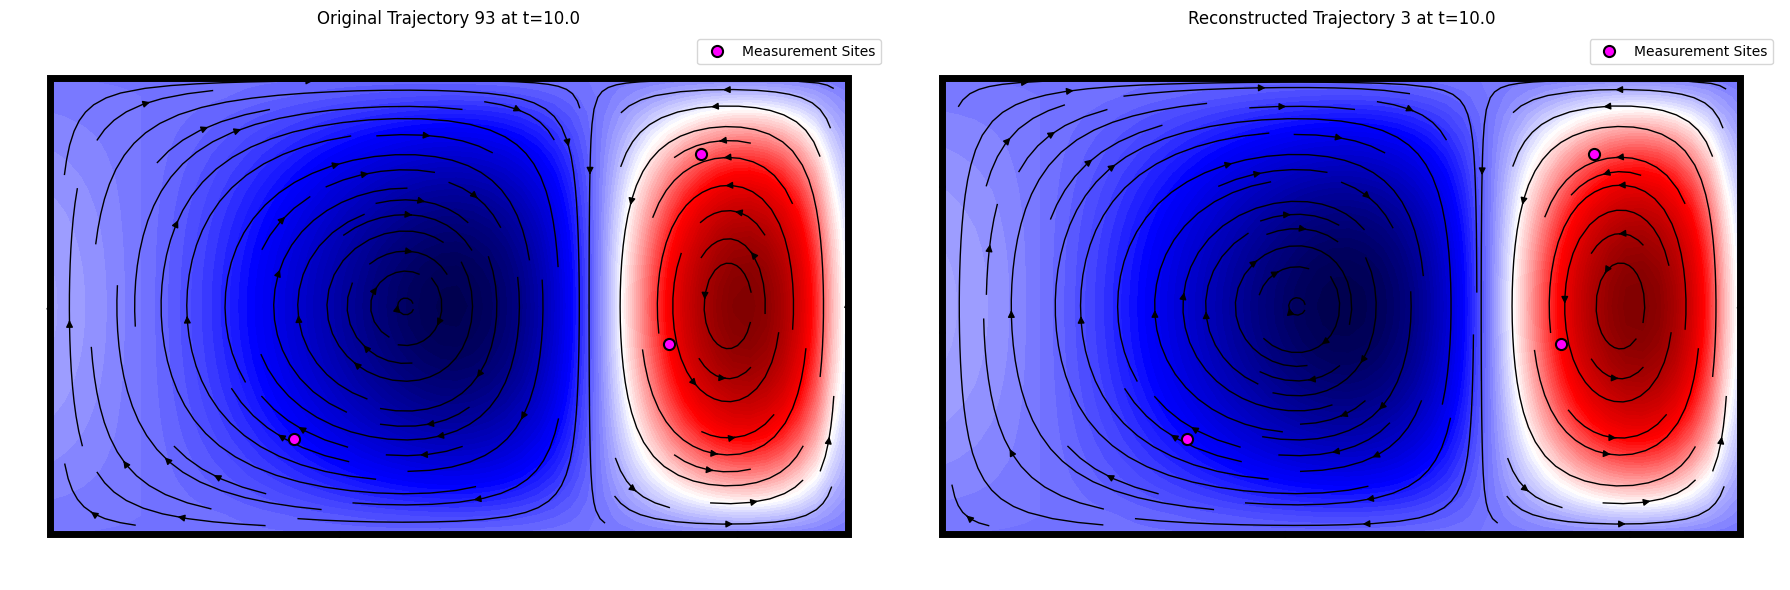

In [82]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)


## Results

In [83]:
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002001,0.002115,0.003069,0.051693,0.054274,0.063563
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000570,0.000621,0.000737,0.026106,0.028349,0.029153
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000427,0.000692,0.000494,0.023380,0.027356,0.024495
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836
7,(mSHRED): TR + MLP,(T.3.B) masking data x2 channels,0.000095,0.000095,0.000120,0.009714,0.011310,0.010306
8,(mSHRED): TR + MLP,(T.3.C) masking hidden space,0.000152,0.000127,0.000161,0.014436,0.015065,0.015629
9,(mSHRED): TR + MLP,(T.3.D) masking attention,0.000144,0.000187,0.000195,0.014519,0.016432,0.015871


In [84]:
# order dataframe by test-mre
print("\nFinal comparison of all models, ordered by test MRE:")
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)


Final comparison of all models, ordered by test MRE:


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
7,(mSHRED): TR + MLP,(T.3.B) masking data x2 channels,0.000095,0.000095,0.000120,0.009714,0.011310,0.010306
10,(mSHRED): TR + MLP,(T.3.D) masking attention + x2 channels,0.000088,0.000099,0.000111,0.012737,0.013826,0.013051
12,(mSHRED): TR + MLP,(T.3.G) masking learned attention + x2 channels,0.000093,0.000111,0.000133,0.013325,0.014386,0.014026
11,(mSHRED): TR + MLP,(T.3.D) masking learned attention,0.000154,0.000168,0.000185,0.014062,0.015411,0.015146
8,(mSHRED): TR + MLP,(T.3.C) masking hidden space,0.000152,0.000127,0.000161,0.014436,0.015065,0.015629
9,(mSHRED): TR + MLP,(T.3.D) masking attention,0.000144,0.000187,0.000195,0.014519,0.016432,0.015871
6,(mSHRED): TR + MLP,(T.3.A) masking data,0.000218,0.000171,0.000228,0.017810,0.017553,0.018836
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000337,0.000377,0.000320,0.017090,0.019148,0.019053
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000150,0.000297,0.000256,0.015751,0.020227,0.019853
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000209,0.000358,0.000352,0.018986,0.024183,0.023041


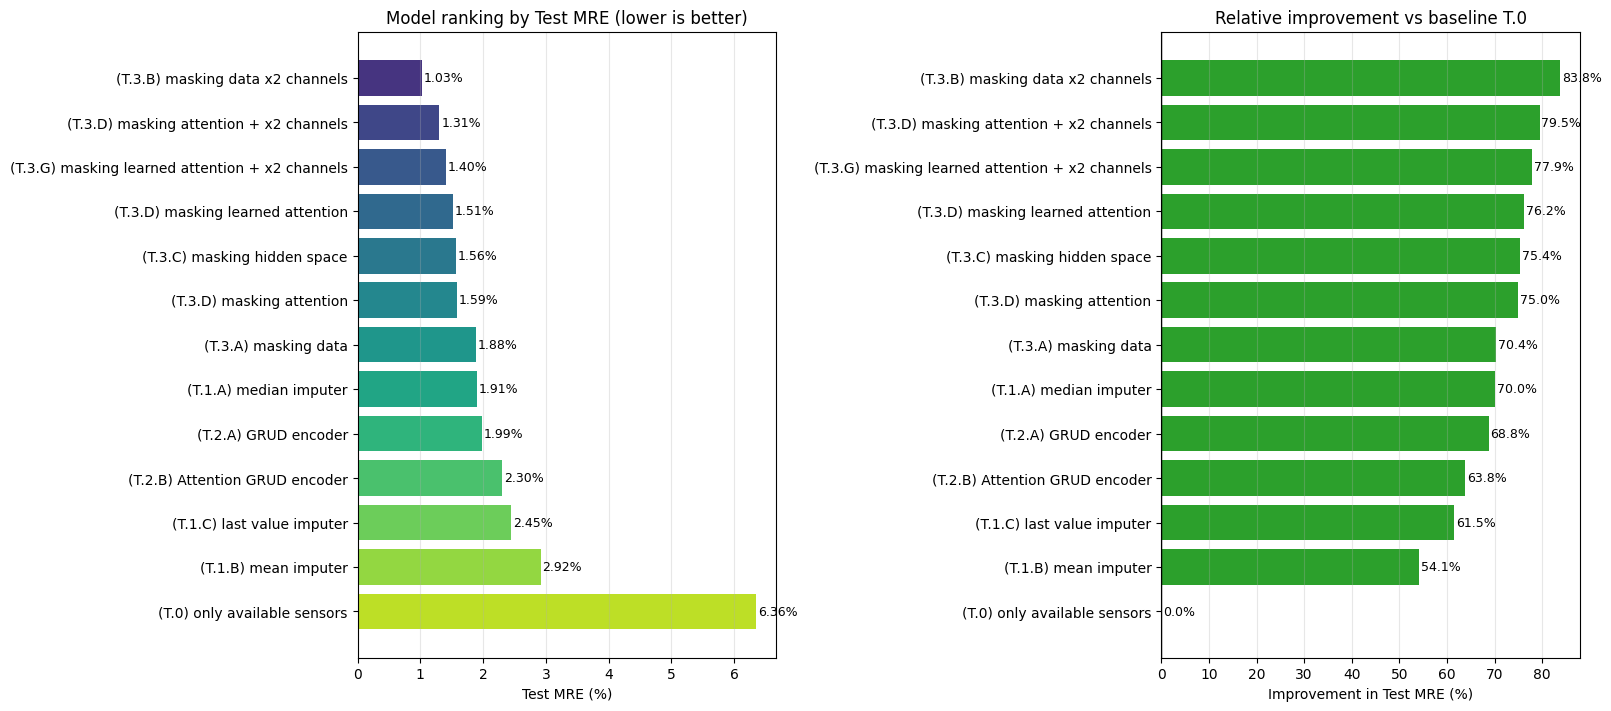

In [86]:
# Meaningful summary plot: ranking + improvement vs baseline
df_plot = dataframe_errors.sort_values("test-mre").reset_index(drop=True)

# Baseline = T.0 (only available sensors)
baseline_mask = df_plot["type"].str.contains("T.0", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(df_plot)))
axes[0].barh(df_plot["type"], df_plot["test-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9)

# --- Right: Improvement vs baseline (T.0) ---
imp_colors = ["tab:green" if x >= 0 else "tab:red" for x in df_plot["improvement_vs_T0_%"]]
axes[1].barh(df_plot["type"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline T.0")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.4 if v >= 0 else -2.5), i, f"{v:.1f}%", va="center", fontsize=9)

plt.show()